# **Project 1**
Name: Maddox Guthrie \
Id: 12184185

# 1.1 Exercise: Fruit Classification using PCA and Logistic Regression

## 1.1.1 Objective:

The objective of this assignment is to explore the effect of dimensionality reduction on classification performance and computation time. You will use the fruit dataset, apply scaling and PCA, and then train a Logistic Regression model. You’ll evaluate how the number of PCA components affects model performance and training time.

## 1.1.2 Part 1: Load Data and Visualization

Load the dataset and explore the images.
1. Load the dataset from `fruits.npz`
2. Extract:
    - X (image data)
    - y (labels)
3. Plot **10 random images** in a **$2 \times 5$ grid**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# load fruits_64x64.npz
data = np.load("fruits.npz")

In [3]:
# get input X and y
X = data["X"]
y = data["y"]

In [4]:
# pick 10 random indices
indices = np.random.choice(X.shape[0], 10, replace=False)

In [5]:
index_to_fruit = {
    1: "Apple",
    2: "Avocado",
    3: "Banana",
    4: "Cherry",
    5: "Corn",
    6: "Mango",
    7: "Orange",
    8: "Pear",
    9: "Plum",
    10: "Strawberry"
}

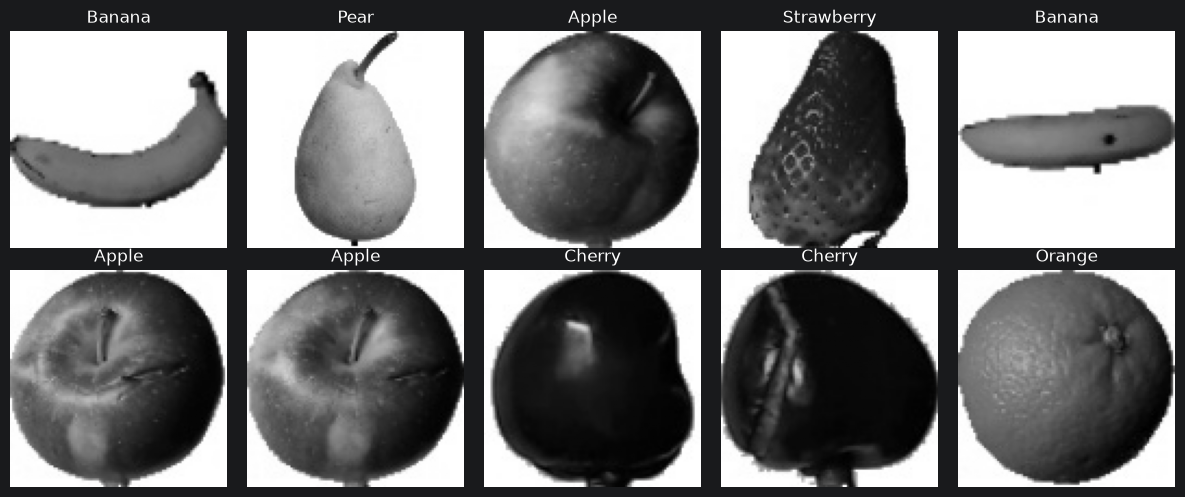

In [6]:
fig, axs = plt.subplots(2, 5, figsize=(12, 5))

for ax, idx in zip(axs.flatten(), indices):
    ax.imshow(X[idx].reshape(100, 100), cmap="gray")
    ax.axis("off")
    ax.set_title(index_to_fruit[y[idx]])

plt.tight_layout()
plt.show()

## 1.1.3 Part 2: Standardization and Logistic Regression (Baseline Model)

You will preprocess the data and train a Logistic Regression model without PCA.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

In [8]:
# 1. Train/Test Split
# 1. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [9]:
# 2. Standardize the inputs
scaler = StandardScaler()

In [10]:
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

In [11]:
# 3. Logistic Regression Model
model = LogisticRegression()

# 4. Fit model
model.fit(X_train_std, y_train)

# 5. Predict
y_pred = model.predict(X_test_std)
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 1.0


In [12]:
# 6. Evaluate the model without PCA
score = model.score(X_test_std, y_test)
print("Score:", score)

Score: 1.0


## 1.1.4 Part 3: PCA + Logistic Regression

Now apply PCA for dimensionality reduction.
- Step 1: Apply PCA (k = 50)
- Step 2: Train Model on PCA Data
- Step 3: Evaluate PCA Model

**Questions**
- Compare:
    - Baseline accuracy
    - PCA accuracy
- Did PCA improve or reduce performance?
- What is the trade-off between dimensionality reduction and accuracy?

In [13]:
# 7. Apply PCA (k = 50)
pca = PCA(n_components=50)
X_train_pca = pca.fit_transform(X_train_std)
X_test_pca = pca.transform(X_test_std)

# 8. Train model on PCA data
model_pca = LogisticRegression(max_iter=1000)
model_pca.fit(X_train_pca, y_train)

# 9. Evaluate PCA model
pca_score = model_pca.score(X_test_pca, y_test)
print("Baseline accuracy:", score)
print("PCA accuracy:", pca_score)

Baseline accuracy: 1.0
PCA accuracy: 1.0


The baseline accuracy is $1.0$ and PCA accuracy is $1.0$, so they are equal. This did not improve or reduce the performance, meaning that $50$ components kept all the necessary information. You get the same accuracy with fewer features, so training is faster and uses less memory. The cost is that the components are harder to interpret than the original features, and with a smaller $k$ you could start losing accuracy.

## 1.1.5 Part 4: Choosing k Based on Explained Variance

You will determine how many principal components are needed to retain 90% of the score.
- Step 1: Fit PCA Without Limiting Components
- Step 2: Compute Cumulative Explained Variance
- Step 3: Find k for 90% Variance

In [14]:
# Step 1: Fit PCA without limiting components
pca_full = PCA()
pca_full.fit(X_train_std)

# Step 2: Cumulative explained variance
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

# Step 3: Smallest k that reaches 90% variance
k_90 = np.argmax(cum_var >= 0.90) + 1
print("k for 90% variance:", k_90)

k for 90% variance: 63


$k = 63$ components are needed to retain $90\%$ of the variance. $63$ is $13$ more components than $50$, so $k = 50$ keeps a little less than 90% of the variance. Both are a large cut from the original number of features. I would pick $k = 63$ over $50$. It has a clear rule behind it instead of an arbitrary number, and it only costs $13$ more features.